# Tutorial answers in Python

Tutorial Q4 asks you to repeat Q1–Q3 in Python. These answers use the same recursion as `Tutorial Answers.xlsx`, with 1,000
customers each and a fixed seed. Times are in minutes.

*Made for this site. NumPy and Matplotlib only, so there is nothing to install.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
N = 1000

def single_server(iat, service):
    """One FIFO server, the same recursion as the Excel sheets:
    Arrival(n) = Arrival(n-1) + IAT(n); Start(n) = max(Arrival(n), End(n-1)); End(n) = Start(n) + Service(n)."""
    arrival = np.cumsum(iat)
    start = np.empty_like(arrival); end = np.empty_like(arrival)
    prev_end = 0.0
    for n in range(len(arrival)):
        start[n] = max(arrival[n], prev_end)
        end[n] = start[n] + service[n]
        prev_end = end[n]
    wait = start - arrival                                    # time in queue
    idle = start - np.concatenate(([0.0], end[:-1]))          # server idle before each customer
    return arrival, start, end, wait, idle

## Q1: M/M/1 bank, λ = 1/3 and μ = 2/3 per minute

Theory: W = λ/(μ(μ−λ)) = 1.5 minutes in the queue; T = 1/(μ−λ) = 3 minutes in the system.

Average time in queue  1.54 (theory 1.50)
Average time in system 3.00 (theory 3.00)


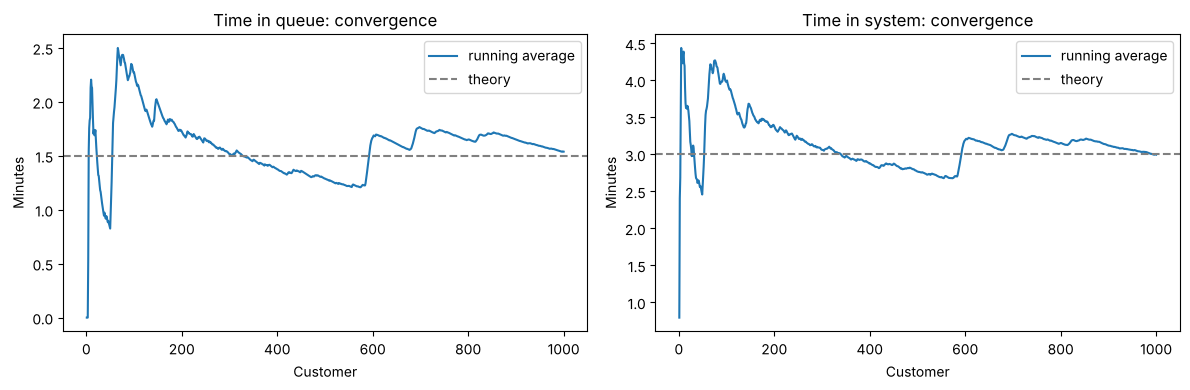

In [2]:
lam, mu = 1 / 3, 2 / 3
arrival, start, end, wait, idle = single_server(rng.exponential(1 / lam, N), rng.exponential(1 / mu, N))
tis = end - arrival
k = np.arange(1, N + 1)
print(f"Average time in queue  {wait.mean():.2f} (theory {lam / (mu * (mu - lam)):.2f})")
print(f"Average time in system {tis.mean():.2f} (theory {1 / (mu - lam):.2f})")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k, np.cumsum(wait) / k, label="running average"); ax[0].axhline(1.5, color="grey", ls="--", label="theory")
ax[0].set(xlabel="Customer", ylabel="Minutes", title="Time in queue: convergence"); ax[0].legend()
ax[1].plot(k, np.cumsum(tis) / k, label="running average"); ax[1].axhline(3, color="grey", ls="--", label="theory")
ax[1].set(xlabel="Customer", ylabel="Minutes", title="Time in system: convergence"); ax[1].legend()
plt.tight_layout(); plt.show()

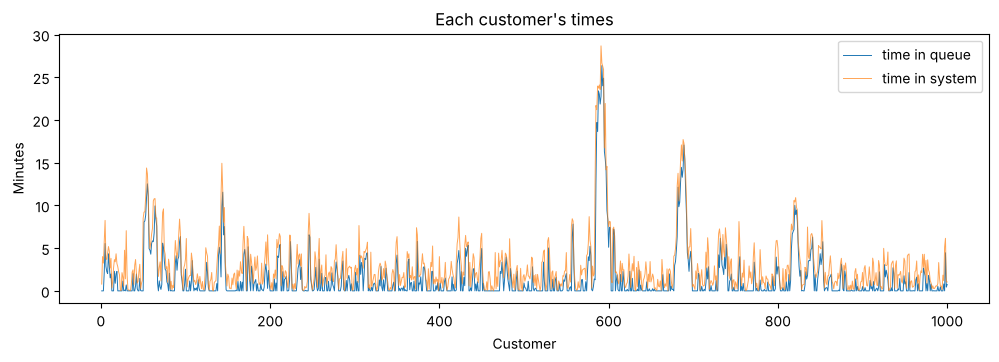

With λ = 1/6: average time in queue 0.58 (theory 0.50). Fewer arrivals, far less queueing.


In [3]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(k, wait, lw=0.7, label="time in queue"); ax.plot(k, tis, lw=0.7, alpha=0.7, label="time in system")
ax.set(xlabel="Customer", ylabel="Minutes", title="Each customer's times"); ax.legend(); plt.show()

lam2 = 1 / 6
_, _, _, w2, _ = single_server(rng.exponential(1 / lam2, N), rng.exponential(1 / mu, N))
print(f"With λ = 1/6: average time in queue {w2.mean():.2f} (theory {lam2 / (mu * (mu - lam2)):.2f}). Fewer arrivals, far less queueing.")

## Q2: one machine with Normal(5, 1) processing, one job every 10 minutes on average

With λ = 0.1 the machine is busy about 50% of the time. Increasing λ shows the limit: the queue cannot recover once λ ≥ 1/5 = 0.2, the machine's maximum rate.

In [4]:
for lam in (0.1, 0.15, 0.18, 0.19, 0.2, 0.22):
    arrival, start, end, wait, idle = single_server(rng.exponential(1 / lam, N), rng.normal(5, 1, N))
    print(f"λ = {lam:.2f}: average time in queue {wait.mean():7.2f}, in system {(end - arrival).mean():7.2f}, "
          f"wait of the last 100 jobs {wait[-100:].mean():7.2f}")

λ = 0.10: average time in queue    2.54, in system    7.57, wait of the last 100 jobs    1.68
λ = 0.15: average time in queue    8.71, in system   13.65, wait of the last 100 jobs    5.14
λ = 0.18: average time in queue   26.74, in system   31.70, wait of the last 100 jobs   64.19
λ = 0.19: average time in queue   28.35, in system   33.35, wait of the last 100 jobs   56.87
λ = 0.20: average time in queue   84.33, in system   89.27, wait of the last 100 jobs  178.56
λ = 0.22: average time in queue  133.45, in system  138.45, wait of the last 100 jobs  315.82


## Q3: three machines in series, Normal (5, 1), (2, 0.3), (3, 0.5)

The slowest stage averages 5 minutes, so with λ = 0.1 every stage is at most 50% busy: the system is stable. Time in queue below counts waiting at all three stages. (The Excel answer counts stage 1 only; erratum C12.)

In [5]:
lam = 0.1
t = np.cumsum(rng.exponential(1 / lam, N)); arrival0 = t.copy(); total_wait = np.zeros(N)
for m, s in ((5, 1), (2, 0.3), (3, 0.5)):
    _, start, end, wait, idle = single_server(np.diff(np.concatenate(([0.0], t))), rng.normal(m, s, N))
    total_wait += wait; t = end
print(f"Average time in queue (all stages) {total_wait.mean():.2f} min, average time in system {(t - arrival0).mean():.2f} min")

Average time in queue (all stages) 2.94 min, average time in system 12.91 min
